# Calculus and Optimization in R

Calculus deals with rates of change (**derivatives**) and accumulation (**integrals**).
Optimization finds the maximum or minimum values of functions — it is how every statistical model and every machine-learning model is fitted.

In R:
- **Derivatives** can be computed symbolically with packages like `Deriv` (or base R's `D()`) or numerically using small step differences.
- **Integrals** can be computed with `integrate()`.
- **Optimization** can be done with `optimize()` (1-D) or `optim()` (multi-dimensional).

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Key Definitions

**Derivative** (slope of the tangent line):
$$
f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}
$$

**Definite integral** (signed area under the curve):
$$
\int_a^b f(x)\,dx
$$

**Critical points** are where $f'(x) = 0$. A critical point is a *local* minimum if $f''(x) > 0$ and a *local* maximum if $f''(x) < 0$. On a closed interval $[a, b]$, the **global** extremes can also occur at the **endpoints** — a detail that is easy to forget.

In [2]:
if (!requireNamespace("Deriv", quietly = TRUE)) install.packages("Deriv")
library(Deriv)

In [3]:
# Define a function: f(x) = x^3 - 2x^2 + 3
f <- function(x) x^3 - 2*x^2 + 3

## 2. Derivatives: Symbolic vs Numerical

In [4]:
f_prime  <- Deriv(f, "x")          # f'(x)  = 3x^2 - 4x
f_second <- Deriv(f_prime, "x")    # f''(x) = 6x - 4
print("Symbolic first derivative f'(x):");  print(body(f_prime))
print("Symbolic second derivative f''(x):"); print(body(f_second))

# Numerical derivative with a central difference
num_deriv <- function(g, x, h = 1e-5) (g(x + h) - g(x - h)) / (2 * h)

cat("\nSlope at x = 2  -> symbolic:", f_prime(2), "| numerical:", round(num_deriv(f, 2), 6), "\n")

[1] "Symbolic first derivative f'(x):"


x * (3 * x - 4)


[1] "Symbolic second derivative f''(x):"


6 * x - 4



Slope at x = 2  -> symbolic: 4 | numerical: 4 


## 3. Integration

In [5]:
integral_result <- integrate(f, lower = 0, upper = 3)
print("Definite integral of f(x) from 0 to 3:")
print(integral_result)

# Check with the antiderivative F(x) = x^4/4 - 2x^3/3 + 3x
F <- function(x) x^4 / 4 - 2 * x^3 / 3 + 3 * x
cat("Exact value F(3) - F(0) =", F(3) - F(0), "\n")

[1] "Definite integral of f(x) from 0 to 3:"


11.25 with absolute error < 1.2e-13


Exact value F(3) - F(0) = 11.25 


## 4. Optimization: Local vs Global Extremes

Solving $f'(x) = 3x^2 - 4x = x(3x - 4) = 0$ gives two critical points: $x = 0$ and $x = 4/3$.

- $f''(0) = -4 < 0$ → **local maximum** at $x = 0$, $f(0) = 3$
- $f''(4/3) = 4 > 0$ → **local minimum** at $x = 4/3$, $f(4/3) \approx 1.815$

But on the interval $[-1, 3]$ we must also check the endpoints: $f(-1) = 0$ and $f(3) = 12$. So the **global maximum is at the endpoint $x = 3$** and the **global minimum is at the endpoint $x = -1$** — not at the critical points!

`optimize()` searches for a *local* extremum, so it can silently miss the global answer. Let's see this happen.

In [6]:
interval <- c(-1, 3)

# What optimize() reports
min_opt <- optimize(f, interval)
max_opt <- optimize(function(x) -f(x), interval)
cat("optimize() minimum: x =", round(min_opt$minimum, 4), " f(x) =", round(min_opt$objective, 4), "\n")
cat("optimize() maximum: x =", round(max_opt$minimum, 4), " f(x) =", round(-max_opt$objective, 4),
    "  <- only a LOCAL maximum\n\n")

# The correct procedure: evaluate f at critical points AND endpoints
crit <- c(0, 4/3)
candidates <- data.frame(x = c(interval[1], crit, interval[2]),
                         type = c("endpoint", "critical", "critical", "endpoint"))
candidates$f_x   <- f(candidates$x)
candidates$f_xx  <- f_second(candidates$x)
print(round_df <- transform(candidates, x = round(x, 4), f_x = round(f_x, 4)), row.names = FALSE)

global_min <- candidates[which.min(candidates$f_x), ]
global_max <- candidates[which.max(candidates$f_x), ]
cat("\nGlobal minimum on [-1, 3]: x =", global_min$x, " f(x) =", global_min$f_x, "\n")
cat("Global maximum on [-1, 3]: x =", global_max$x, " f(x) =", global_max$f_x, "\n")

optimize() minimum: x = 1.3333  f(x) = 1.8148 


optimize() maximum: x = 0  f(x) = 3   <- only a LOCAL maximum



       x     type     f_x f_xx
 -1.0000 endpoint  0.0000  -10
  0.0000 critical  3.0000   -4
  1.3333 critical  1.8148    4
  3.0000 endpoint 12.0000   14



Global minimum on [-1, 3]: x = -1  f(x) = 0 


Global maximum on [-1, 3]: x = 3  f(x) = 12 


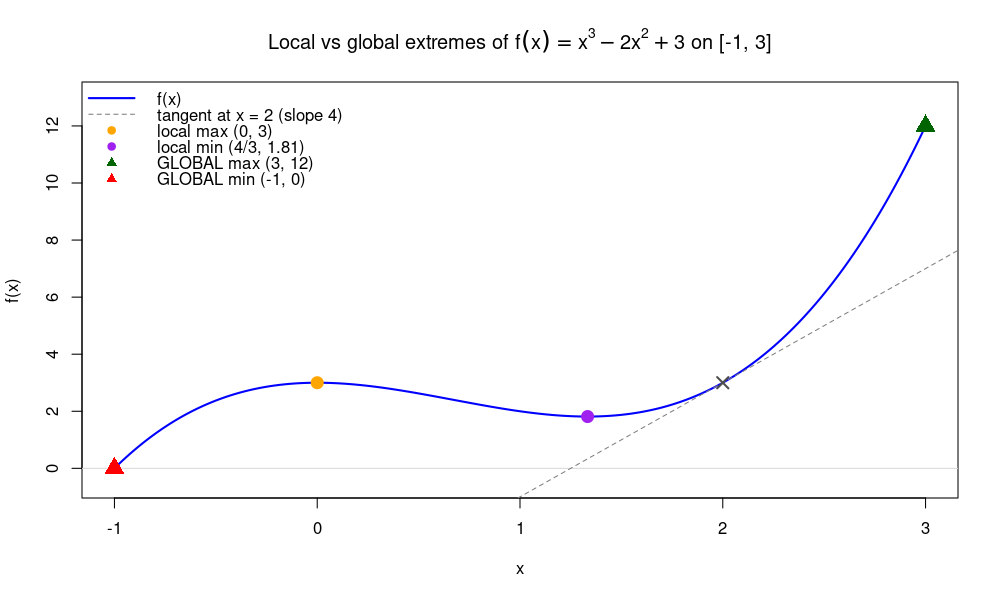

In [7]:
x_vals <- seq(-1, 3, by = 0.01)
plot(x_vals, f(x_vals), type = "l", lwd = 2, col = "blue",
     main = expression("Local vs global extremes of" ~ f(x) == x^3 - 2*x^2 + 3 ~ "on [-1, 3]"),
     xlab = "x", ylab = "f(x)", ylim = c(-0.5, 13))
abline(h = 0, col = "grey85")

# tangent line at x = 2 (slope 4)
abline(a = f(2) - f_prime(2) * 2, b = f_prime(2), col = "grey50", lty = 2)
points(2, f(2), pch = 4, cex = 1.5, lwd = 2, col = "grey30")

points(0, f(0), pch = 19, cex = 1.6, col = "orange")
points(4/3, f(4/3), pch = 19, cex = 1.6, col = "purple")
points(global_max$x, global_max$f_x, pch = 17, cex = 2, col = "darkgreen")
points(global_min$x, global_min$f_x, pch = 17, cex = 2, col = "red")

legend("topleft", bty = "n",
       legend = c("f(x)", "tangent at x = 2 (slope 4)", "local max (0, 3)", "local min (4/3, 1.81)",
                  "GLOBAL max (3, 12)", "GLOBAL min (-1, 0)"),
       col = c("blue", "grey50", "orange", "purple", "darkgreen", "red"),
       lty = c(1, 2, NA, NA, NA, NA), lwd = c(2, 1, NA, NA, NA, NA), pch = c(NA, NA, 19, 19, 17, 17))

*Insight: Optimizers find **a** low point, not necessarily **the** lowest point. In machine learning this is the "local minimum" problem — which is why models are often trained from several random starting points.*

## 5. Gradient Descent by Hand

Gradient descent repeatedly takes a small step **downhill**, against the derivative:

$$
x_{t+1} = x_t - \eta \, f'(x_t)
$$

where $\eta$ is the **learning rate**. This is exactly the algorithm used to train neural networks (Section 09).

Learning rate 0.05  -> ends at x = 1.334 


Learning rate 0.005 -> ends at x = 1.8605 (too slow, not converged)


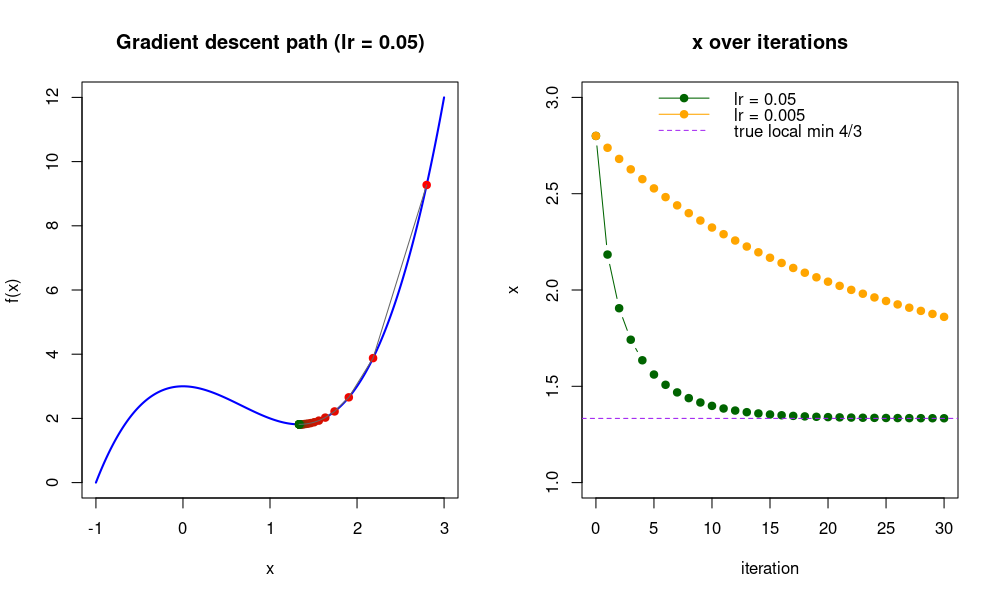

In [8]:
gradient_descent <- function(x0, lr = 0.1, steps = 30) {
  path <- numeric(steps + 1); path[1] <- x0
  for (t in 1:steps) path[t + 1] <- path[t] - lr * f_prime(path[t])
  path
}

path_good  <- gradient_descent(x0 = 2.8, lr = 0.05)
path_small <- gradient_descent(x0 = 2.8, lr = 0.005)
cat("Learning rate 0.05  -> ends at x =", round(tail(path_good, 1), 4), "\n")
cat("Learning rate 0.005 -> ends at x =", round(tail(path_small, 1), 4), "(too slow, not converged)\n")

par(mfrow = c(1, 2))
plot(x_vals, f(x_vals), type = "l", lwd = 2, col = "blue", main = "Gradient descent path (lr = 0.05)",
     xlab = "x", ylab = "f(x)")
points(path_good, f(path_good), pch = 19, col = colorRampPalette(c("red", "darkgreen"))(length(path_good)))
lines(path_good, f(path_good), col = "grey40")

plot(0:30, path_good, type = "b", pch = 19, col = "darkgreen", ylim = c(1, 3),
     main = "x over iterations", xlab = "iteration", ylab = "x")
lines(0:30, path_small, type = "b", pch = 19, col = "orange")
abline(h = 4/3, lty = 2, col = "purple")
legend("topright", c("lr = 0.05", "lr = 0.005", "true local min 4/3"),
       col = c("darkgreen", "orange", "purple"), lty = c(1, 1, 2), pch = c(19, 19, NA), bty = "n")

## 6. Multi-dimensional Optimization with `optim()`

Most real problems have several parameters. `optim()` minimises a function of a vector. Here we minimise the classic **Rosenbrock** function, whose minimum is at $(1, 1)$:

$$
g(a, b) = (1 - a)^2 + 100\,(b - a^2)^2
$$

In [9]:
rosen <- function(p) (1 - p[1])^2 + 100 * (p[2] - p[1]^2)^2
fit <- optim(c(-1.2, 1), rosen, method = "BFGS")
cat("Minimum found at (a, b) =", round(fit$par, 4), " with g =", signif(fit$value, 3),
    " | converged:", fit$convergence == 0, "\n")

Minimum found at (a, b) = 0.9998 0.9996  with g = 3.83e-08  | converged: TRUE 


## Real-World Use Case or Analogy

- **Derivative**: checking how fast a car is moving at an exact second.
- **Integral**: measuring the total distance the car travelled between two points in time.
- **Optimization**: finding the lowest fuel consumption over a trip.
- **Local vs global extremes**: a hiker in fog who walks downhill until the ground is flat may be standing in a small dip halfway up the mountain, not in the deepest valley. Checking the **boundaries** (endpoints) and trying **several starting points** are the hiker's map and compass.

Calculus powers economics, physics, engineering, and AI model training — optimization is the "tuning" step that produces the best model.